In [1]:
%pylab inline
import gc
import anautil
import numpy as np
import scipy
import astropy.io.fits as pyfits
import astropy.io.ascii as ascii

import matplotlib.lines as mlines

Populating the interactive namespace from numpy and matplotlib


In [2]:
cd /work/xiangchong.li/work/cosmicShear

/work/xiangchong.li/work/cosmicShear


# index

This notebook serves to analysis the output chains of cosmosis, which includes

- Smoothing with KDE
- Finding Contour

In [29]:
#infname='./analysis1-mockana/hsc_iabias.txt'
#infname='./analysis2-y1/noisy/n01.txt'
infname='./analysis2-y1/hsc_nobias.txt'
#infname='./analysis2-y1/hsc_bin1cutsom.txt'
#infname='./ref/cfhtlens/example_b.txt'
out=anautil.read_cosmosis_chain(infname)

LOADING CHAIN FROM FILE:  ./analysis2-y1/hsc_nobias.txt


In [30]:
import scipy.stats.kde as kde
class KDE(kde.gaussian_kde):
    def __init__(self, points, factor=1.0, weights=None):
        points = np.array(np.atleast_2d(points))
        self._factor = factor
        d, n = points.shape
        self.norms = []
        normalized_points = []

        for column in points:
            col_mean = column.mean()
            col_std = column.std()
            self.norms.append((col_mean,col_std))
            normalized_points.append((column-col_mean)/col_std)
        super(KDE,self).__init__(normalized_points, weights=weights)

    def covariance_factor(self):
        return self.scotts_factor() * self._factor

    def grid_evaluate(self, n, ranges):
        if isinstance(ranges,tuple):
            ranges = [ranges]
        slices = [slice(xmin,xmax,n*1j) for (xmin,xmax) in ranges]
        grids = np.mgrid[slices]
        axes = [ax.squeeze() for ax in np.ogrid[slices]]
        flats = [(grid.flatten()-norm[0])/norm[1]
                 for (grid,norm) in zip(grids,self.norms)]

        shape = grids[0].shape
        flats = np.array(flats)
        like_flat = self.evaluate(flats)
        like = like_flat.reshape(*shape)
        if len(axes)==1:
            axes = axes[0]
        return axes,like

    def normalize_and_evaluate(self, points):
        points = np.array([(p-norm[0])/norm[1] for norm, p in zip(self.norms, points)])
        return self.evaluate(points)

def smooth_likelihood(x, y, w=None):
    n = 100
    fill = True
    kde = KDE([x,y],factor=2.5, weights=w)
    mu_x = np.average(x, weights=w)
    mu_y = np.average(y, weights=w)
    dx=np.sqrt((w*(x-mu_x)**2.).sum()/w.sum())*4.
    dy=np.sqrt((w*(y-mu_y)**2.).sum()/w.sum())*4.
    #dx=np.sqrt(((x-mu_x)**2.).sum()/len(x))*4.
    #dy=np.sqrt(((y-mu_y)**2.).sum()/len(y))*4.
    print(mu_x,mu_y,dx,dy)

    x_range = (max(x.min(), mu_x-dx), min(x.max(), mu_x+dx))
    y_range = (max(y.min(), mu_y-dy), min(y.max(), mu_y+dy))
    (x_axis, y_axis), like = kde.grid_evaluate(n, [x_range, y_range])
    return n, x_axis, y_axis, like        

def find_contours(like,x,y,w,n,xmin,xmax,ymin,ymax,contour1,contour2):
    N = len(x)
    x_axis = np.linspace(xmin, xmax, n+1)
    y_axis = np.linspace(ymin, ymax, n+1)
    histogram, _, _ = np.histogram2d(x, y, bins=[x_axis, y_axis], weights=w/np.nanmax(w))
    plt.imshow(histogram)
    def objective(limit, target):
        msk = np.where(like>=limit)
        count = histogram[msk]
        return count.sum() - target
    target1 = histogram.sum()*(1-contour1)
    target2 = histogram.sum()*(1-contour2)
    print(target1,target2)

    level1 = scipy.optimize.bisect(objective, like.min(), like.max(), args=(target1,))
    level2 = scipy.optimize.bisect(objective, like.min(), like.max(), args=(target2,))
    return level1, level2, like.sum()

0.9234898057068035 0.2978599093393546 0.3643305959709555 0.23308669993739214
0.559159209735848 1.287820401677759
0.10022042393684388 0.5309466092767468
797.6708051948069 1114.3930366692155
436.6189886177305


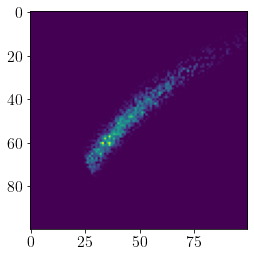

In [31]:
name1='sigma_8'
name2='omega_m'

#Get the data
x = out[name1]
y = out[name2]
if 'weight' in out.dtype.names:
    w=out['weight']
else:
    w=np.ones_like(out)
assert (x.max()-x.min()>0)&(y.max()-y.min()>0)

mu_x = np.average(x, weights=w)
mu_y = np.average(y, weights=w)

# using KDE
n, x_axis, y_axis, like = smooth_likelihood(x, y, w)
print(x_axis[0],x_axis[-1])
print(y_axis[0],y_axis[-1])

#Choose levels at which to plot contours
contour1=1-0.68; contour2=1-0.95
level1, level2, total_mass = find_contours(like, x, y,w,n, x_axis[0], x_axis[-1], y_axis[0], y_axis[-1], contour1, contour2)
print(total_mass)

level0 = np.inf
levels = [level2, level1, level0]

(array([   8.,    7.,   10.,    4.,   20.,  129.,  102.,  141.,  226.,
        2756.]),
 array([-100. ,  -90.1,  -80.2,  -70.3,  -60.4,  -50.5,  -40.6,  -30.7,
         -20.8,  -10.9,   -1. ]),
 <BarContainer object of 10 artists>)

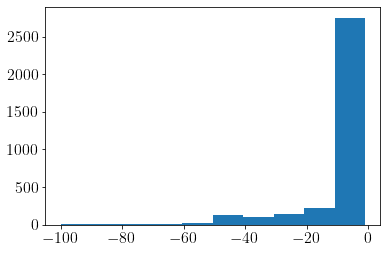

In [32]:
plt.hist(np.log10(out['weight']),range=(-100,-1))

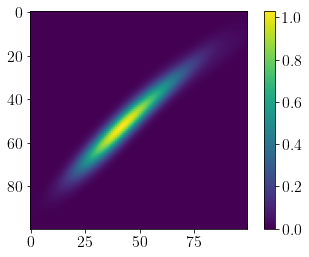

In [33]:
plt.imshow(like)
plt.colorbar()

0.9234898057068035 0.2978599093393546


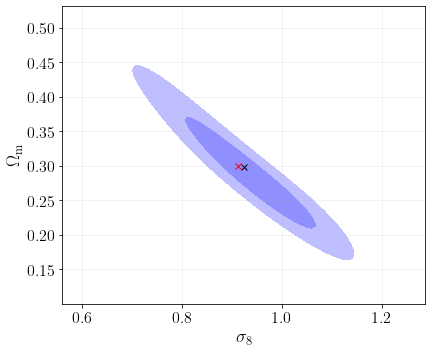

In [34]:
plt.close()
plt.figure(figsize=(6,5))
latexDict={'omega_m': r'$\Omega_{\rm m}$',
           'sigma_8': r'$\sigma_8$',
           'sigma8_input': r'$\sigma_8$',
           'a_s': r'$A_s$',
           'n_s': r'$n_s$'}
color='b'
fill = True
imshow = False

if imshow:
    plt.imshow(like.T, extent=(x_axis[0], x_axis[-1], y_axis[0], y_axis[-1]), aspect='auto', origin='lower')
    plt.colorbar()
elif fill:
    light= pylab.matplotlib.colors.ColorConverter().to_rgb(color)
    dark = (light[0], light[1], light[2], 0.2)
    plt.contourf(x_axis, y_axis, like.T, [level2,level0], colors=[light], alpha=0.25)
    plt.contourf(x_axis, y_axis, like.T, [level1,level0], colors=[dark], alpha=0.25)
    
#Do the labels
plt.xlabel(latexDict[name1])
plt.ylabel(latexDict[name2])
plt.tight_layout()
mu_x = np.average(x, weights=w)
mu_y = np.average(y, weights=w)

plt.plot(mu_x,mu_y,'x',c='black')
true_x,true_y=(0.912,0.300)
plt.plot(true_x,true_y,'x',c='red')
print(mu_x,mu_y)
plt.grid(alpha=0.2)

LOADING CHAIN FROM FILE:  ./analysis2-y1/noisy/n01.txt
LOADING CHAIN FROM FILE:  ./analysis2-y1/noisy/n02.txt
LOADING CHAIN FROM FILE:  ./analysis2-y1/noisy/n03.txt
LOADING CHAIN FROM FILE:  ./analysis2-y1/noisy/n04.txt
LOADING CHAIN FROM FILE:  ./analysis2-y1/noisy/n05.txt
LOADING CHAIN FROM FILE:  ./analysis2-y1/noisy/n06.txt
LOADING CHAIN FROM FILE:  ./analysis2-y1/noisy/n07.txt
LOADING CHAIN FROM FILE:  ./analysis2-y1/noisy/n08.txt
LOADING CHAIN FROM FILE:  ./analysis2-y1/noisy/n09.txt
LOADING CHAIN FROM FILE:  ./analysis2-y1/noisy/n10.txt


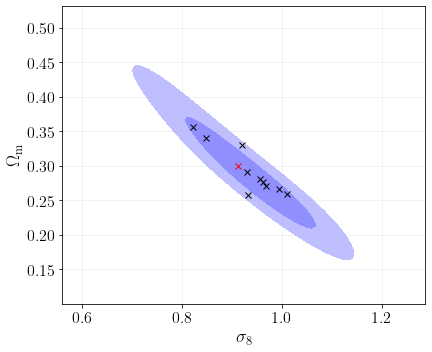

In [35]:
plt.close()
plt.figure(figsize=(6,5))
light= pylab.matplotlib.colors.ColorConverter().to_rgb(color)
dark = (light[0], light[1], light[2], 0.2)
plt.contourf(x_axis, y_axis, like.T, [level2,level0], colors=[light], alpha=0.25)
plt.contourf(x_axis, y_axis, like.T, [level1,level0], colors=[dark], alpha=0.25)
for i in range(1,11):
    infname='./analysis2-y1/noisy/n%02d.txt' %i
    outTmp=anautil.read_cosmosis_chain(infname)
    mu_x = np.average(outTmp[name1], weights=outTmp['weight'])
    mu_y = np.average(outTmp[name2], weights=outTmp['weight'])
    plt.plot(mu_x,mu_y,'x',c='black')
true_x,true_y=(0.912,0.300)
plt.plot(true_x,true_y,'x',c='red')
plt.grid(alpha=0.2)

plt.xlabel(latexDict[name1])
plt.ylabel(latexDict[name2])
plt.tight_layout()

LOADING CHAIN FROM FILE:  ./analysis2-y1/hsc_bin1cutcut.txt
LOADING CHAIN FROM FILE:  ./analysis2-y1/hsc_bin2cutdp.txt


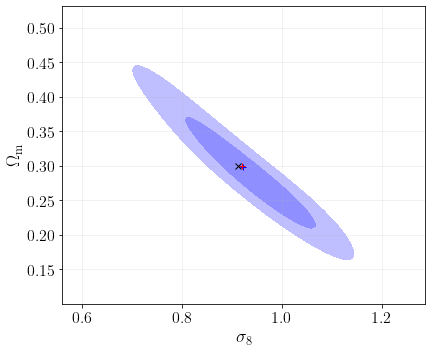

In [38]:
plt.close()
plt.figure(figsize=(6,5))
light= pylab.matplotlib.colors.ColorConverter().to_rgb(color)
dark = (light[0], light[1], light[2], 0.2)
plt.contourf(x_axis, y_axis, like.T, [level2,level0], colors=[light], alpha=0.25)
plt.contourf(x_axis, y_axis, like.T, [level1,level0], colors=[dark], alpha=0.25)
infname='./analysis2-y1/hsc_bin1cutcut.txt'
outTmp=anautil.read_cosmosis_chain(infname)
mu_x = np.average(outTmp[name1], weights=outTmp['weight'])
mu_y = np.average(outTmp[name2], weights=outTmp['weight'])
plt.plot(mu_x,mu_y,'+',c='blue')

infname='./analysis2-y1/hsc_bin2cutdp.txt'
outTmp=anautil.read_cosmosis_chain(infname)
mu_x = np.average(outTmp[name1], weights=outTmp['weight'])
mu_y = np.average(outTmp[name2], weights=outTmp['weight'])
plt.plot(mu_x,mu_y,'+',c='red')


true_x,true_y=(0.912,0.300)
plt.plot(true_x,true_y,'x',c='black')
plt.grid(alpha=0.2)

plt.xlabel(latexDict[name1])
plt.ylabel(latexDict[name2])
plt.tight_layout()